<a href="https://colab.research.google.com/github/ashwathraj/DataScience_AI/blob/FCFNN---MLP/FCFNN_MNIST.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [30]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# MNIST dataset
train_dataset = torchvision.datasets.MNIST(root='./data',
                                           train=True,
                                           transform=transforms.ToTensor(),
                                           download=True)

test_dataset = torchvision.datasets.MNIST(root='./data',
                                          train=False,
                                          transform=transforms.ToTensor())

# Data loader
train_loader = torch.utils.data.DataLoader(dataset=train_dataset,
                                           batch_size=100,
                                           shuffle=True)

test_loader = torch.utils.data.DataLoader(dataset=test_dataset,
                                          batch_size=100,
                                          shuffle=False)

# Quick verification of data shape
examples = iter(train_loader)
samples, labels = next(examples)
print(f"Samples shape: {samples.shape}, Labels shape: {labels.shape}")

Using device: cpu
Samples shape: torch.Size([100, 1, 28, 28]), Labels shape: torch.Size([100])


=== Batch Structure ===
Type of images: <class 'torch.Tensor'>
Type of labels: <class 'torch.Tensor'>
Images Batch Shape (Batch Size, Channels, Height, Width): torch.Size([100, 1, 28, 28])
Labels Batch Shape: torch.Size([100])
Images pixel range: Min=0.000, Max=1.000
First 10 Labels: [2, 1, 7, 9, 6, 5, 3, 6, 2, 1]


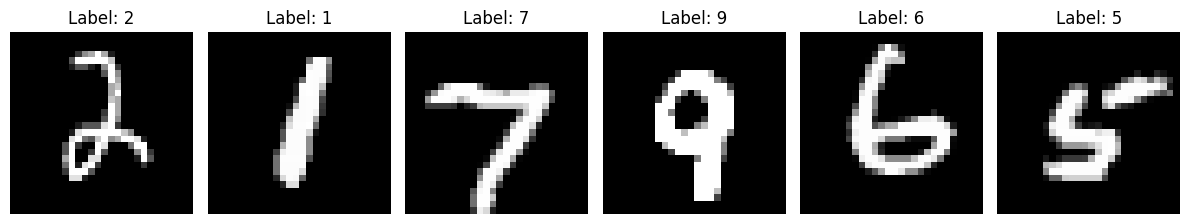

In [31]:
# Inspect the structure of the PyTorch DataLoader
images, labels = next(iter(train_loader))
print("=== Batch Structure ===")
print(f"Type of images: {type(images)}")
print(f"Type of labels: {type(labels)}")
print(f"Images Batch Shape (Batch Size, Channels, Height, Width): {images.shape}")
print(f"Labels Batch Shape: {labels.shape}")
print(f"Images pixel range: Min={images.min().item():.3f}, Max={images.max().item():.3f}")
print(f"First 10 Labels: {labels[:10].tolist()}")

# Visualize a few examples from the batch
fig, axes = plt.subplots(1, 6, figsize=(12, 3))
for i in range(6):
    axes[i].imshow(images[i].squeeze(), cmap='gray')
    axes[i].set_title(f"Label: {labels[i].item()}")
    axes[i].axis('off')
plt.tight_layout()
plt.show()